In [31]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [33]:
df = pd.read_excel('diamonds_new.xlsx')
df.head()

,price,carat,cut,color,clarity,depth,table,x,y,z
0,326,0.23,Ideal,E,SI2,61.5,55.0,3.95,3.98,2.43
1,326,0.21,Premium,E,SI1,59.8,61.0,3.89,3.84,2.31
2,327,0.23,Good,E,VS1,56.9,65.0,4.05,4.07,2.31
3,334,0.29,Premium,I,VS2,62.4,58.0,4.20,4.23,2.63
4,335,0.31,Good,J,SI2,63.3,58.0,4.34,4.35,2.75


In [34]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 53920 entries, 0 to 53919
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   price    53920 non-null  int64  
 1   carat    53920 non-null  float64
 2   cut      53920 non-null  str    
 3   color    53920 non-null  str    
 4   clarity  53920 non-null  str    
 5   depth    53920 non-null  float64
 6   table    53920 non-null  float64
 7   x        53920 non-null  float64
 8   y        53920 non-null  float64
 9   z        53920 non-null  float64
dtypes: float64(6), int64(1), str(3)
memory usage: 4.1 MB


In [35]:
df.describe()

,price,carat,depth,table,x,y,z
count,53920.000000,53920.000000,53920.000000,53920.000000,53920.000000,53920.000000,53920.000000
mean,3933.492174,0.798018,61.749560,57.456769,5.731337,5.734703,3.538854
std,3989.963677,0.474061,1.432414,2.233927,1.121807,1.142192,0.705736
min,326.000000,0.200000,43.000000,43.000000,0.000000,0.000000,0.000000
25%,950.000000,0.400000,61.000000,56.000000,4.710000,4.720000,2.910000
50%,2401.000000,0.700000,61.800000,57.000000,5.700000,5.710000,3.530000
75%,5327.000000,1.040000,62.500000,59.000000,6.540000,6.540000,4.040000
max,18823.000000,5.010000,79.000000,95.000000,10.740000,58.900000,31.800000


In [36]:
df.columns

Index(['price', 'carat', 'cut', 'color', 'clarity', 'depth', 'table', 'x', 'y',
       'z'],
      dtype='str')

In [37]:
df.dtypes

price        int64
carat      float64
cut            str
color          str
clarity        str
depth      float64
table      float64
x          float64
y          float64
z          float64
dtype: object

In [38]:
display_count = df.isnull().sum()
print(display_count)

price      0
carat      0
cut        0
color      0
clarity    0
depth      0
table      0
x          0
y          0
z          0
dtype: int64


In [39]:
df.shape

(53920, 10)

In [40]:
duplicate_count = df.duplicated().sum()
print("duplicated rows:", duplicate_count)

duplicated rows: 146


In [42]:
df_clean = df.drop_duplicates().copy()
print("shape of dataset after removing duplicates:", pd_clean.shape)

shape of dataset after removing duplicates: (53774, 10)


In [ ]:
df_clean

,price,carat,cut,color,clarity,depth,table,x,y,z
0,326,0.23,Ideal,E,SI2,61.5,55.0,3.95,3.98,2.43
1,326,0.21,Premium,E,SI1,59.8,61.0,3.89,3.84,2.31
2,327,0.23,Good,E,VS1,56.9,65.0,4.05,4.07,2.31
3,334,0.29,Premium,I,VS2,62.4,58.0,4.20,4.23,2.63
4,335,0.31,Good,J,SI2,63.3,58.0,4.34,4.35,2.75
...,...,...,...,...,...,...,...,...,...,...
53915,2757,0.72,Ideal,D,SI1,60.8,57.0,5.75,5.76,3.50
53916,2757,0.72,Good,D,SI1,63.1,55.0,5.69,5.75,3.61
53917,2757,0.70,Very Good,D,SI1,62.8,60.0,5.66,5.68,3.56
53918,2757,0.86,Premium,H,SI2,61.0,58.0,6.15,6.12,3.74


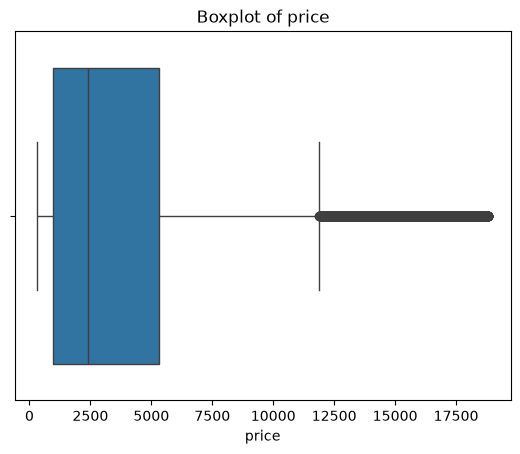

951.0 5328.75 4377.75 -5615.625 11895.375
flagged: 3523


In [49]:
col = "price"
sns.boxplot(x=df_clean[col])
plt.title(f"Boxplot of {col}")
plt.show()

q1 = df_clean[col].quantile(0.25)
q3 = df_clean[col].quantile(0.75)
iqr = q3-q1

lower = q1-1.5*iqr
upper = q3+1.5*iqr
flag = (df_clean[col]<lower) | (df_clean[col]>upper)
print(q1,q3,iqr,lower,upper)
print("flagged:", flag.sum())



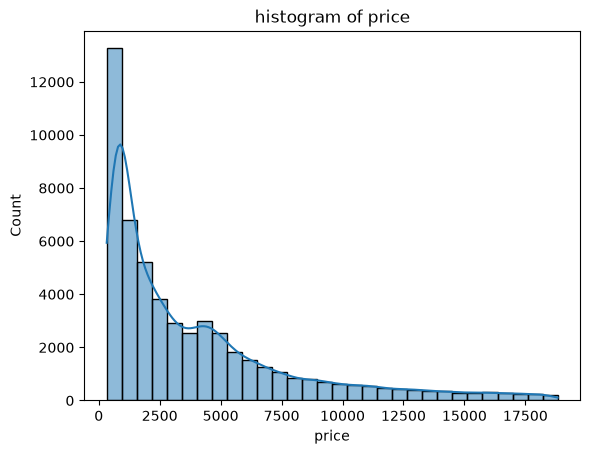

In [51]:
sns.histplot(data=df_clean, x= "price", bins=30, kde=True)
plt.title(f"histogram of price")
plt.show()

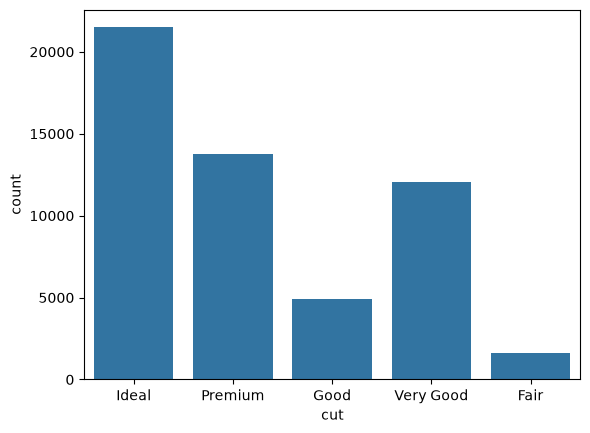

In [52]:
sns.countplot(data=df_clean, x="cut")
plt.show()

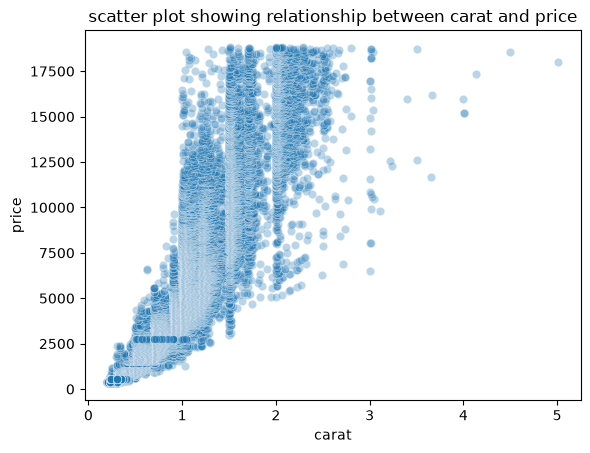

In [55]:
sns.scatterplot(data=df_clean, x="carat", y="price", alpha=0.3)
plt.title(f"scatter plot showing relationship between carat and price")
plt.show()

price    1.000000
carat    0.921547
x        0.884529
y        0.865413
z        0.861219
table    0.126703
depth   -0.011075
Name: price, dtype: float64


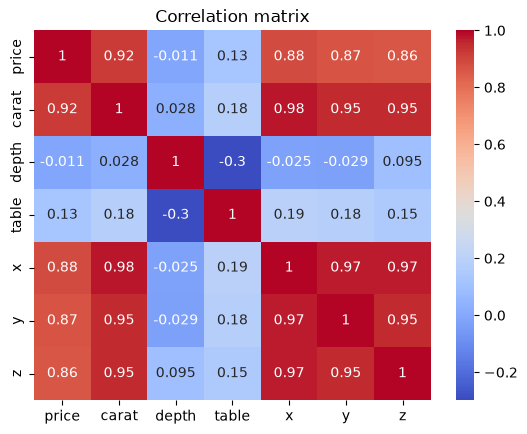

In [60]:
num = df_clean.select_dtypes(include="number")

print(num.corr()["price"].sort_values(ascending=False))

sns.heatmap( num.corr(), annot=True, cmap="coolwarm")
plt.title("Correlation matrix")
plt.show()

Carat is most strongly and positively correlated with price (0.92). Depth and table are almost uncorrelated with price. Correlation shows association, not causation.

In [61]:
print(num.corr(method="spearman")["price"].sort_values(ascending=False))

price    1.000000
x        0.963240
carat    0.962900
y        0.962765
z        0.957284
table    0.171148
depth    0.010216
Name: price, dtype: float64


Spearman correlation shows carat, x, y and z all have a very strong positive monotonic relationship with price (about 0.96), while table and depth are weak. The higher Spearman than Pearson value suggests the relationship is curved rather than perfectly linear."